# 1つの変数の分布
生存との関係を見る前に、各変数がどのような値をとっているか(分布)を確認します。数値の変数は要約統計量とヒストグラム、カテゴリの変数は度数と割合で調べます。

## 学習目標
- `describe` で数値の変数の要約統計量を求め、特徴を読み取れる
- `value_counts` でカテゴリの変数の度数と割合を求められる
- ヒストグラムを描き、分布の偏り(歪み)と外れ値を確認できる
- 右に裾の長い変数を対数変換すると分布が見やすくなることを説明できる

## 予測の対象(Survived)の分布

まず、予測の対象である `Survived` の割合を確認します。`value_counts(normalize=True)` で、各値の割合が求まります。

In [1]:
import pandas as pd

# 学習用のデータを読み込む
train = pd.read_csv("train.csv")

# value_counts で値ごとの件数を数える。normalize=True を付けると件数ではなく割合になる
train["Survived"].value_counts(normalize=True).round(3)

Survived
0    0.626
1    0.374
Name: proportion, dtype: float64


学習用のデータでは、生存した乗客は約 37% です。何も考えずに「全員死亡」と予測しても正解率は約 63% になります。モデルの精度は、この **基準(ベースライン)** と比べて評価します。

## 数値の変数:要約統計量

`describe()` で、数値の変数の件数・平均・標準偏差・最小値・四分位数・最大値をまとめて求められます。

In [2]:
# [[...]] で複数の列を選び、describe() で要約統計量をまとめて求める
train[["Age", "Fare", "SibSp", "Parch"]].describe().round(2)

          Age    Fare   SibSp   Parch
count  718.00  890.00  891.00  891.00
mean    30.48   34.10    0.51    0.38
std     14.36   52.91    1.08    0.87
min      0.67    0.00    0.00    0.00
25%     21.00    7.90    0.00    0.00
50%     29.00   14.25    0.00    0.00
75%     39.00   31.50    1.00    0.00
max     76.00  512.33    8.00    9.00


- `Age`:件数が 718 で、891 人のうち約 2 割が欠損。平均 30.5 歳、中央値(50%)29 歳
- `Fare`:平均 34.1 に対して中央値は 14.25 と大きく離れ、最大は 512.33。**一部の高額な運賃に平均が引っ張られている**(右に裾の長い分布)
- `SibSp`・`Parch`:中央値は 0。多くの乗客は家族なしで乗船している

## 数値の変数:ヒストグラム

ヒストグラムで分布の形を確認します。グラフの文字は英語で書きます(日本語のフォントがないため)。

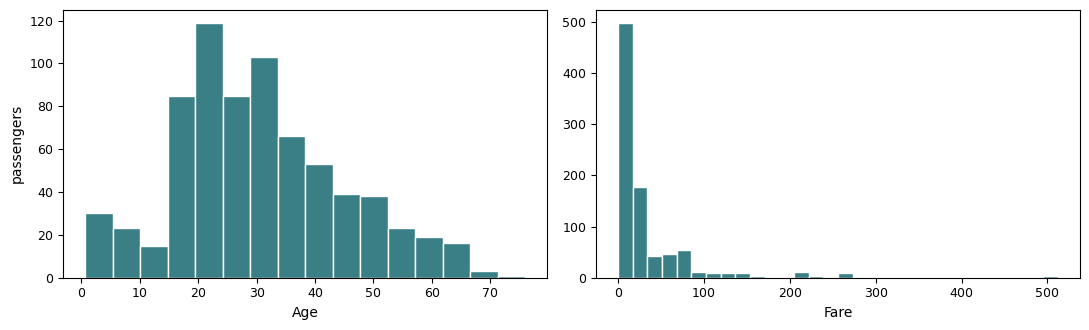

In [3]:
# グラフを描くライブラリ matplotlib を、plt という短い名前で読み込む
import matplotlib.pyplot as plt

# 1 行 2 列のグラフの枠(axes[0] と axes[1])を作る。figsize は図の横・縦の大きさ(インチ)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

# 左:年齢のヒストグラム。dropna() で欠損値を除き、bins で柱の数を指定する
axes[0].hist(train["Age"].dropna(), bins=16)
axes[0].set_xlabel("Age")          # 横軸のラベル
axes[0].set_ylabel("passengers")   # 縦軸のラベル

# 右:運賃のヒストグラム
axes[1].hist(train["Fare"].dropna(), bins=30)
axes[1].set_xlabel("Fare")

# 図の余白を自動で整えて表示する
fig.tight_layout()
plt.show()

年齢は 20〜30 代を中心とした山で、0〜5 歳の子どもにも小さな山があります。運賃は 0〜50 にほとんどが集まり、右に長い裾があります。

右に裾の長い変数は、**対数変換** すると分布の形が見やすくなります。運賃 0 の乗客もいるため、`np.log1p`(1 を足してから対数をとる)を使います。

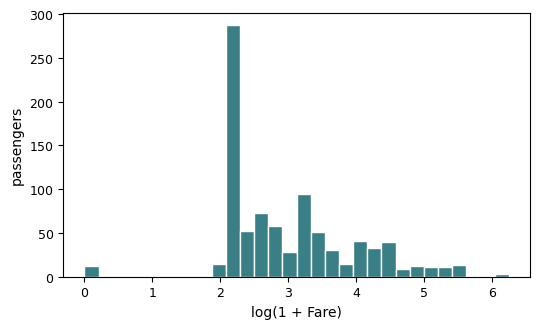

In [4]:
# 数値計算のライブラリ numpy を、np という短い名前で読み込む
import numpy as np

# グラフの枠を 1 つ作る
fig, ax = plt.subplots(figsize=(5.5, 3.4))
# np.log1p で「1 + 運賃」の対数をとってから、ヒストグラムを描く
ax.hist(np.log1p(train["Fare"].dropna()), bins=30)
ax.set_xlabel("log(1 + Fare)")
ax.set_ylabel("passengers")
fig.tight_layout()
plt.show()

対数をとると、裾の長さが縮まり、いくつかの山(等級ごとの運賃の違い)が見えるようになります。

## カテゴリの変数:度数と割合

カテゴリの変数は、`value_counts` で値ごとの人数を数えます。

In [5]:
# 等級ごとの人数を数え、sort_index() で等級(1, 2, 3)の順に並べる
train["Pclass"].value_counts().sort_index()

Pclass
1    217
2    196
3    478
Name: count, dtype: int64


3 等の乗客が 478 人で、半数以上を占めます。

## 演習

学習用のデータで、乗船した港 `Embarked` の **割合** を求め、小数第3位まで表示してください(欠損値は除いて計算されます)。

In [ ]:
# @starter
import pandas as pd

# 学習用のデータを読み込む
train = pd.read_csv("train.csv")

# 乗船した港ごとの割合を求めて、小数第3位まで表示する
# (____ に、件数ではなく割合にするための引数を入れる)
print(train["Embarked"].value_counts(____).round(3))

In [6]:
# @solution
# @title: 乗船した港の割合
# @hint: value_counts に normalize=True を指定すると、人数ではなく割合になります。
# @explanation: Southampton(S)から乗船した乗客が約 69% と大部分を占め、Cherbourg(C)が約 21%、Queenstown(Q)が約 10% です。
import pandas as pd

# 学習用のデータを読み込む
train = pd.read_csv("train.csv")

# 乗船した港ごとの割合(normalize=True)を求めて、小数第3位まで表示する
print(train["Embarked"].value_counts(normalize=True).round(3))

Embarked
S    0.691
C    0.211
Q    0.098
Name: proportion, dtype: float64


学習用のデータで、**客室の等級(`Pclass`)ごと** の運賃 `Fare` の中央値を求め、小数第2位まで表示してください。

In [ ]:
# @starter
import pandas as pd

# 学習用のデータを読み込む
train = pd.read_csv("train.csv")

# 等級ごとのグループに分けて運賃の中央値を求め、小数第2位まで表示する
# (____ に、中央値を求めるメソッドの名前を入れる)
print(train.groupby("Pclass")["Fare"].____().round(2))

In [7]:
# @solution
# @title: 等級ごとの運賃の中央値
# @hint: グループごとの中央値は median() で求めます。運賃は右に裾が長いので、平均より中央値の方が代表的な値を表します。
# @explanation: 運賃の中央値は 1 等が約 71、2 等が約 15、3 等が約 8 で、等級が上がるほど高くなります。運賃は客室の等級と強く関係しています。
import pandas as pd

# 学習用のデータを読み込む
train = pd.read_csv("train.csv")

# 等級ごとのグループに分けて運賃の中央値を求め、小数第2位まで表示する
print(train.groupby("Pclass")["Fare"].median().round(2))

Pclass
1    71.28
2    15.05
3     7.92
Name: Fare, dtype: float64


<!-- @question
type: choice
answer: 一部の非常に高い運賃に平均が引っ張られているため。
title: 運賃の平均と中央値
hint: 運賃のヒストグラムの形と、最大値の大きさを思い出しましょう。
explanation: 運賃は右に裾が長い分布で、最大 512 という非常に高い運賃があります。平均はこうした大きな値に引っ張られて大きくなりますが、中央値は真ん中の順位の値なので影響を受けにくく、平均の方が大きくなります。
-->
学習用のデータで、運賃の平均(約 34.1)が中央値(14.25)よりかなり大きい理由として最も適切なものを選べ。

- 運賃の欠損値が 0 として計算されているため。
- 一部の非常に高い運賃に平均が引っ張られているため。
- 運賃が左に裾の長い分布であるため。
- 中央値は 1 等の乗客だけから計算されるため。

## まとめ

- 予測の対象の割合(生存 約 37%)は、モデルを評価するときの基準になる。
- `describe` で要約統計量を確認し、平均と中央値の差から分布の偏りを読み取る。運賃は右に裾が長く、対数変換すると見やすくなる。
- カテゴリの変数は `value_counts`(`normalize=True` で割合)で確認する。